$$\Phi_h(t) = \int_{-\infty}^{\infty} dx h(x) \phi(t,x)$$
$$ C(s) = \langle 0 | \Phi_h(s) \Phi_h(0)| 0 \rangle  $$
$$ \Rightarrow C(s) = \int_{-\infty}^{\infty} \frac{dk}{2 \pi}\frac{|\tilde{h}(k)|^2}{2 \omega_k} e^{-i \omega_k s} $$

$$ \Rightarrow C(s) = \int_{-\infty}^{\infty} \frac{dk}{2 \pi}\frac{|\tilde{h}(k)|^2}{2 \omega_k} cos(\omega_k s) - i\int_{-\infty}^{\infty} \frac{dk}{2 \pi}\frac{|\tilde{h}(k)|^2}{2 \omega_k} sin(\omega_k s)  $$

In [46]:
import numpy as np
from scipy.integrate import quad , trapezoid
import matplotlib.pyplot as plt


In [47]:
def comp_htilde_p(h,x_max,x_min , k_grid):
    def ft_h(k_val):
        r,_ = quad(lambda x: np.real(h(x) * np.exp(-1j * k_val * x)) , x_min , x_max , limit= 200)
        i , _ = quad(lambda x: np.imag(h(x) * np.exp(-1j * k_val * x)) , x_min , x_max , limit= 200)
        return r**2 + i**2
    return np.array([ft_h(k) for  k  in k_grid])

def f_C(s_values ,  h  , m ,  x_max , x_min , k_max , n_k):

    k_grid = np.linspace(0.0 , k_max , n_k)
    omega = np.sqrt(k_grid**2 + m**2)

    h_t = comp_htilde_p(h,x_max,x_min , k_grid)

    W = h_t/(2.0 * np.pi * omega)

    C_val = []
    
    for s in s_values:
        core = W * np.exp(-1j * omega * s)
        val = 2 * np.trapezoid(core , k_grid)
        C_val.append(val)

    return np.array(C_val)
    


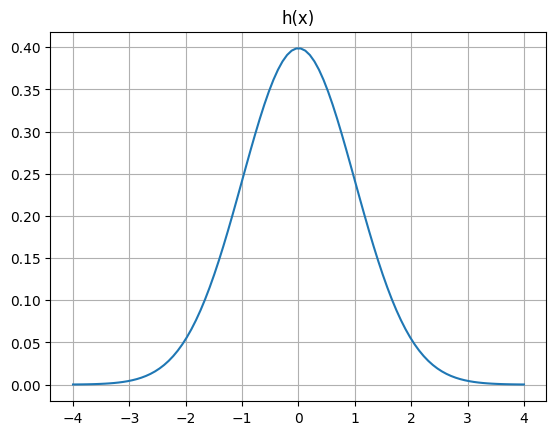

In [48]:
def h_profile(x,sigma_x = 1.0):
    #gausian
    return (np.exp(-x**2 / (2.0 * sigma_x**2)))/(np.sqrt(2.0 * np.pi) * sigma_x)

x =  np.linspace(-4,4,100)
y = h_profile(x , sigma_x = 1.0)
plt.plot(x,y)

plt.title("h(x)")
plt.grid(True)
plt.show()


In [60]:
m = 1.0
sigma_x = 1.0
x_min = -8.0*sigma_x
x_max = -1*x_min
k_max = 10.0/sigma_x
n_k = 1000

t_max = 25.0
n_t = 1500



h = lambda x:h_profile(x,sigma_x = sigma_x)

s_values = np.linspace(0.0, t_max, n_t + 1)
C_values = f_C(s_values ,  h  , m ,  x_max , x_min , k_max , n_k)

for s ,C in zip(s_values[:6] , C_values[:6]):
    print(f"s={s:7.1f}  C(s)={C.real:+.3e}{C.imag:+.3e}j")

s=    0.0  C(s)=+2.426e-01+0.000e+00j
s=    0.0  C(s)=+2.425e-01-4.701e-03j
s=    0.0  C(s)=+2.424e-01-9.401e-03j
s=    0.1  C(s)=+2.421e-01-1.410e-02j
s=    0.1  C(s)=+2.418e-01-1.879e-02j
s=    0.1  C(s)=+2.414e-01-2.347e-02j


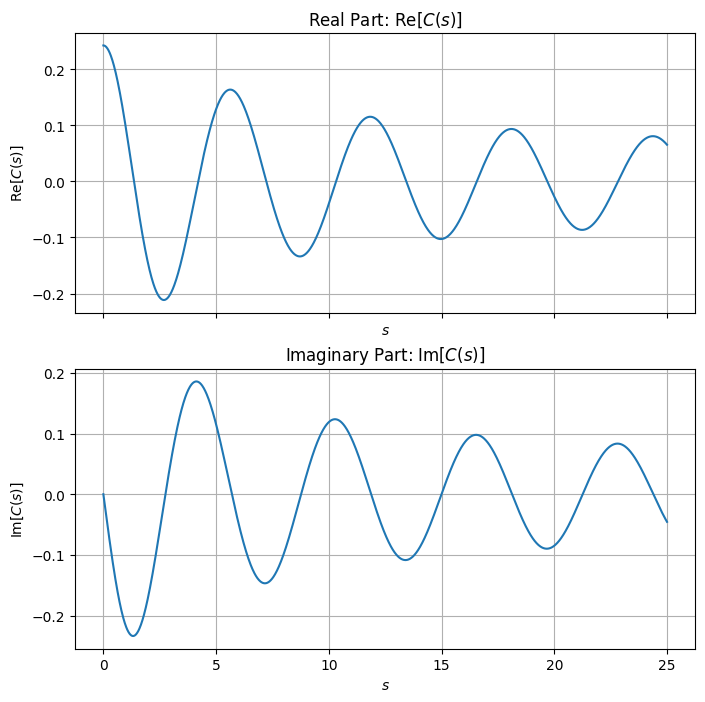

In [61]:
fig , axes = plt.subplots(2,1,figsize=(8, 8), sharex=True)
axes[0].plot(s_values , C_values.real , label =r"$\mathrm{Re}[C(s)]$" )
axes[0].set_title(r"Real Part: $\mathrm{Re}[C(s)]$")
axes[0].set_xlabel(r"$s$")
axes[0].set_ylabel(r"$\mathrm{Re}[C(s)]$")
axes[0].grid(True)


axes[1].plot(s_values, C_values.imag, label=r"$\mathrm{Im}[C(s)]$")
axes[1].set_title(r"Imaginary Part: $\mathrm{Im}[C(s)]$")
axes[1].set_xlabel(r"$s$")
axes[1].set_ylabel(r"$\mathrm{Im}[C(s)]$")
axes[1].grid(True)


$$
\ln \mathcal{J}(t) = -2 \, \Gamma(t)
$$

$$
\Gamma(t)
=
\text{Tr}_\varphi
\left(
R_0
\left(
\epsilon(t)\Phi(t)
-
\epsilon(0)\Phi(0)
+
\int_0^t \dot{\epsilon}(t')\Phi(t')\,dt'
\right)^2
\right)
$$

$$
\epsilon(0) = 0
$$

$$
\Gamma(t)
=
\epsilon(t)^2 C(0)
+
2\epsilon(t)
\int_0^t
\dot{\epsilon}(t')
\mathrm{Re}[C(t-t')]
\,dt'
+
\int_0^t dt'
\int_0^t dt''
\dot{\epsilon}(t')
\dot{\epsilon}(t'')
\mathrm{Re}[C(t'-t'')]
$$

--------------------------

gaussian :
$$\epsilon(t) = \epsilon_0 \left[ \exp\left(-\frac{(t - t_0)^2}{2\sigma^2}\right) - \exp\left(-\frac{t_0^2}{2\sigma^2}\right) \right]$$

periodic:

$$\epsilon(t) = \epsilon_0 \left(1 - e^{-t / \tau_{\text{rise}}}\right) \sin(\omega t)$$


periodic_square:

$$\epsilon(t) = \frac{\epsilon_0}{2} \left[ 1 + \tanh\big(\text{sharpness} \cdot \sin(\omega t)\big) \right] \left(1 - e^{-t}\right)$$

step:

$$\epsilon(t) = \epsilon_0 \left[ \frac{1}{1 + e^{-(t - t_{\text{step}})/\text{width}}} - \frac{1}{1 + e^{t_{\text{step}}/\text{width}}} \right]$$


delta:

$$\epsilon(t) = \frac{\text{area}}{\sqrt{2\pi}\,\text{width}} \left[ \exp\left(-\frac{(t - t_{\text{peak}})^2}{2\,\text{width}^2}\right) - \exp\left(-\frac{t_{\text{peak}}^2}{2\,\text{width}^2}\right) \right]$$




In [62]:

t_grid = np.linspace(0.0, t_max, n_t + 1)
dt = t_grid[1] - t_grid[0]

eps_families = {
    "gausian": lambda t, eps0=1.0, t0=12.0, sigma=2.5: (
        eps0 * np.exp(-((t - t0)**2) / (2.0 * sigma**2)) - eps0 * np.exp(-(t0**2) / (2.0 * sigma**2))
    ),

    "periodic_smooth": lambda t, eps0=1.0, omega=2.0, tau_rise=1.0: (
        eps0 * (1.0 - np.exp(-t / tau_rise)) * np.sin(omega * t)
    ),

    "periodic_square": lambda t, eps0=1.0, omega=1.5, sharpness=15.0: (
        eps0 * 0.5 * (1.0 + np.tanh(sharpness * np.sin(omega * t))) * (1.0 - np.exp(-t))
    ),

    "step": lambda t, eps0=1.0, t_step=2.0, width=0.15: (
        eps0 / (1.0 + np.exp(-(t - t_step) / width)) - eps0 / (1.0 + np.exp(t_step / width))
    ),

    "delta": lambda t, area=1.0, t_peak=2.5, width=0.08: (
        (area / (np.sqrt(2.0 * np.pi) * width)) * (
            np.exp(-((t - t_peak)**2) / (2.0 * width**2)) - np.exp(-(t_peak**2) / (2.0 * width**2))
        )
    )
}

selected_profile = 'gausian'

eps_f = eps_families[selected_profile]
eps_values = eps_f(t_grid)
d_eps_values = np.gradient(eps_values, dt)

In [63]:
C_real = C_values.real
C_0 = C_real[0]
num_pts = len(t_grid)

I_1 = (eps_values ** 2) * C_0  

I_2 = np.zeros(num_pts)
for n in range(1, num_pts):
    d_eps_past = d_eps_values[:n+1]
    C_past = C_real[:n+1][::-1]
    int_val = np.trapezoid(d_eps_past * C_past, dx=dt)
    I_2[n] = 2.0 * eps_values[n] * int_val

d_eps_matrix = np.outer(d_eps_values, d_eps_values)
i, j = np.indices((num_pts, num_pts))
C_matrix = C_real[np.abs(i - j)]
integrand_2D = d_eps_matrix * C_matrix

I_3 = np.zeros(num_pts)
for n in range(1, num_pts):
    past = integrand_2D[:n+1, :n+1]
    I_3[n] = np.trapezoid(np.trapezoid(past, dx=dt, axis=0), dx=dt)

Gamma = I_1 + I_2 + I_3
J_abs = np.exp(-2.0 * Gamma)

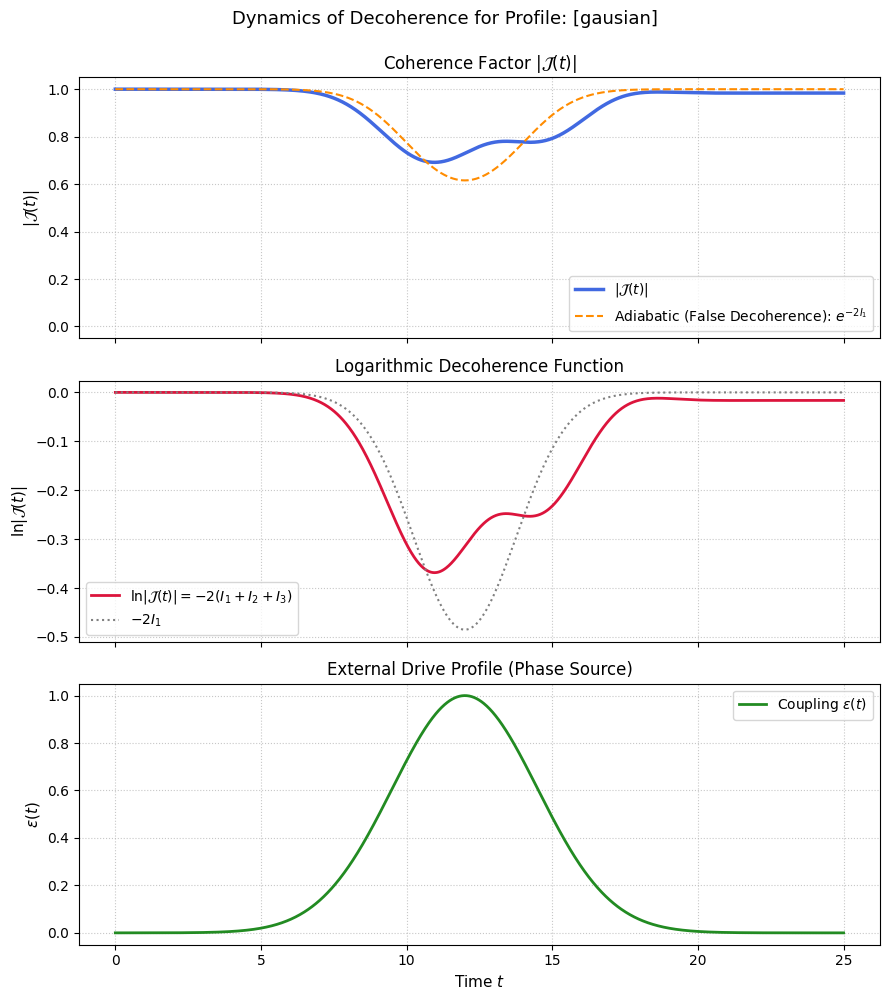

In [64]:

fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)

axes[0].plot(t_grid, J_abs, color="royalblue", lw=2.5, label=r"$|\mathcal{J}(t)|$")
axes[0].plot(t_grid, np.exp(-2.0 * I_1), color="darkorange", ls="--", lw=1.5, label=r"Adiabatic (False Decoherence): $e^{-2 I_1}$")
axes[0].set_ylabel(r"$|\mathcal{J}(t)|$", fontsize=11)
axes[0].set_ylim(-0.05, 1.05)
axes[0].grid(True, ls=":", alpha=0.7)
axes[0].legend(loc="lower right")
axes[0].set_title(r"Coherence Factor $|\mathcal{J}(t)|$", fontsize=12)

axes[1].plot(t_grid, -2.0 * Gamma, color="crimson", lw=2, label=r"$\ln|\mathcal{J}(t)| = -2(I_1 + I_2 + I_3)$")
axes[1].plot(t_grid, -2.0 * I_1, color="gray", ls=":", label=r"$-2 I_1$")
axes[1].set_ylabel(r"$\ln|\mathcal{J}(t)|$", fontsize=11)
axes[1].grid(True, ls=":", alpha=0.7)
axes[1].legend(loc="lower left")
axes[1].set_title(r"Logarithmic Decoherence Function", fontsize=12)

axes[2].plot(t_grid, eps_values, color="forestgreen", lw=2, label=r"Coupling $\epsilon(t)$")
axes[2].set_xlabel(r"Time $t$", fontsize=11)
axes[2].set_ylabel(r"$\epsilon(t)$", fontsize=11)
axes[2].grid(True, ls=":", alpha=0.7)
axes[2].legend(loc="upper right")
axes[2].set_title(r"External Drive Profile (Phase Source)", fontsize=12)

plt.suptitle(f"Dynamics of Decoherence for Profile: [{selected_profile}]", fontsize=13, y=0.995)
plt.tight_layout()
plt.show()